# 08. Calibration and the final test

**Where we are:** notebook 07 built quantile forecasts and found their intervals do not contain
the outcome as often as they should, especially with forecast weather.

**What this notebook does:**

1. Calibrates the intervals with conformal prediction, using only errors known at the time.
2. Runs the model **once** on the test window (June 2024 onwards), with forecast weather, exactly
   as it would have run live.
3. Compares it with NESO's day-ahead forecast and looks at where each does better.

**Background reading**
- [Romano, Patterson and Candès, Conformalized quantile regression (2019)](https://arxiv.org/abs/1905.03222)
- [Angelopoulos and Bates, A gentle introduction to conformal prediction (2021)](https://arxiv.org/abs/2107.07511)
- [Gneiting and Raftery, Strictly proper scoring rules (2007)](https://sites.stat.washington.edu/raftery/Research/PDF/Gneiting2007jasa.pdf), section 6.2 on the interval score


## Step 1. Set up and load


In [1]:
from pathlib import Path

import holidays
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROCESSED = Path("../data/processed")
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e4e0",
    "lines.linewidth": 2,
})

features_actual = pd.read_parquet(PROCESSED / "features_actual.parquet")
features_forecast = pd.read_parquet(PROCESSED / "features_forecast.parquet")
validation = pd.read_parquet(PROCESSED / "validation_quantiles.parquet")
point_validation = pd.read_parquet(PROCESSED / "validation_forecasts.parquet")
point_validation = point_validation[point_validation["model"] == "LightGBM (actual weather)"]
validation = validation.merge(point_validation[["start_utc", "forecast"]].rename(columns={"forecast": "point"}),
                              on="start_utc")
bench = pd.read_parquet(PROCESSED / "neso_benchmark.parquet")

COLUMNS = ["slot", "weekday", "month", "day_of_year", "holiday", "christmas", "lag7", "lag14",
           "similar_day", "level24", "level_ratio", "solar_capacity", "temperature_2m",
           "temp_day_mean", "wind_speed_10m", "shortwave_radiation", "radiation_x_capacity"]
PARAMS = dict(n_estimators=600, learning_rate=0.05, num_leaves=63, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_jobs=4, verbose=-1, random_state=0)
QUANTILES = [0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]
QCOLS = [f"q{q}" for q in QUANTILES]
INTERVALS = [(0.25, 0.75), (0.1, 0.9), (0.05, 0.95)]


def block(slot):
    """Four parts of the local day: night, morning, middle of the day, evening."""
    hour = np.asarray(slot) / 2
    return np.select([hour < 6, hour < 10, hour < 16], ["night", "morning", "midday"], "evening")


def coverage(frame, low, high, lo_col=None, hi_col=None):
    y = frame["Demand_Outturn"]
    return ((y >= frame[lo_col or f"q{low}"]) & (y <= frame[hi_col or f"q{high}"])).mean()


## Step 2. Conformal calibration

**The idea:** look at how far outcomes fell *outside* each interval in the recent past, and
widen (or narrow) the interval by just enough that the right share of past outcomes would have
been inside. For an interval from quantile `lo` to `hi`, each past half-hour gets a score

`score = max(lo − outcome, outcome − hi)`

which is positive when the outcome fell outside and negative when it was inside. For a 90%
interval, the adjustment is the 90th percentile of the scores (with a small correction for
sample size), added to both ends. This is conformalized quantile regression (Romano et al., 2019).

**Why it helps here:** conformal methods promise the target coverage if the future errors behave
like the past ones. They do not need the quantile models to be right, only the recent errors to
be a fair sample of the next ones.

**Which past:** the previous six months of out-of-sample forecasts, rolled forward month by
month, so each month is calibrated only on errors known before it began.

**Three options compared:**
- conformal, one adjustment for the whole day;
- conformal, a separate adjustment for each of four parts of the day (night, morning, middle of
  the day, evening), since notebook 07 found coverage varies through the day;
- notebook 07's reference, the point forecast plus recent errors by half-hour, which is itself a
  simple conformal method built on the point model.

**How to choose:** the 90% *interval score* (Gneiting and Raftery, 2007): the width of the
interval, plus 20 times the distance by which the outcome falls outside it. It is a proper score,
so it rewards narrow intervals only when they still contain the outcome. Lower is better.


In [2]:
def conformal_shift(scores, nominal):
    n = len(scores)
    level = min(1.0, np.ceil((n + 1) * nominal) / n)
    return np.quantile(scores, level, method="higher")


def calibrate(frame, history, by_block):
    """Add calibrated interval ends to frame, using scores from history."""
    out = frame.copy()
    groups_now = block(out["slot"]) if by_block else np.full(len(out), "all")
    groups_past = block(history["slot"]) if by_block else np.full(len(history), "all")
    for low, high in INTERVALS:
        score = np.maximum(history[f"q{low}"] - history["Demand_Outturn"],
                           history["Demand_Outturn"] - history[f"q{high}"])
        shift = {g: conformal_shift(score[groups_past == g], high - low) for g in np.unique(groups_past)}
        delta = pd.Series(groups_now, index=out.index).map(shift)
        out[f"c{low}"] = out[f"q{low}"] - delta
        out[f"c{high}"] = out[f"q{high}"] + delta
    return out


def reference(frame, history):
    """Point forecast plus quantiles of recent errors, separately for each half-hour of the day."""
    out = frame.copy()
    errors = (history["Demand_Outturn"] - history["point"]).groupby(history["slot"])
    for low, high in INTERVALS:
        out[f"c{low}"] = out["point"] + out["slot"].map(errors.quantile(low))
        out[f"c{high}"] = out["point"] + out["slot"].map(errors.quantile(high))
    return out


def interval_score(frame, low=0.05, high=0.95, lo_col="c0.05", hi_col="c0.95"):
    y, lo, hi = frame["Demand_Outturn"], frame[lo_col], frame[hi_col]
    alpha = 1 - (high - low)
    return ((hi - lo) + 2 / alpha * ((lo - y).clip(lower=0) + (y - hi).clip(lower=0))).mean()


METHODS = {
    "conformal, global": lambda frame, history: calibrate(frame, history, by_block=False),
    "conformal, by time of day": lambda frame, history: calibrate(frame, history, by_block=True),
    "point + recent errors": reference,
}
folds = sorted(validation["fold"].unique())
calibrated = {}
for name, method in METHODS.items():
    parts = []
    for i, fold in enumerate(folds[6:], start=6):
        history = validation[validation["fold"].isin(folds[i - 6:i])]
        parts.append(method(validation[validation["fold"] == fold], history))
    calibrated[name] = pd.concat(parts, ignore_index=True)

raw = validation[validation["fold"].isin(folds[6:])]
rows = {"raw quantiles": {**{f"{h - l:.0%} coverage": coverage(raw, l, h) for l, h in INTERVALS},
                          "90% width (MW)": (raw["q0.95"] - raw["q0.05"]).mean(),
                          "90% interval score (MW)": interval_score(raw, lo_col="q0.05", hi_col="q0.95")}}
for name, frame in calibrated.items():
    rows[name] = {**{f"{h - l:.0%} coverage": coverage(frame, l, h, f"c{l}", f"c{h}") for l, h in INTERVALS},
                  "90% width (MW)": (frame["c0.95"] - frame["c0.05"]).mean(),
                  "90% interval score (MW)": interval_score(frame)}
comparison = pd.DataFrame(rows).T
comparison.round(3)


,50% coverage,80% coverage,90% coverage,90% width (MW),90% interval score (MW)
raw quantiles,0.292,0.567,0.735,2633.974,5929.285
"conformal, global",0.498,0.794,0.892,3798.801,5114.004
"conformal, by time of day",0.498,0.794,0.892,3824.049,5047.899
point + recent errors,0.479,0.766,0.871,3158.036,4765.168


In [3]:
gap = {}
for name, frame in [("raw", raw), *calibrated.items()]:
    lo, hi = ("q0.05", "q0.95") if name == "raw" else ("c0.05", "c0.95")
    inside = (frame["Demand_Outturn"] >= frame[lo]) & (frame["Demand_Outturn"] <= frame[hi])
    gap[name] = inside.groupby(block(frame["slot"])).mean()
by_part = pd.DataFrame(gap).round(3)
by_part.loc["mean width of 90% interval (MW)"] = [
    (raw["q0.95"] - raw["q0.05"]).mean(),
    *[(f["c0.95"] - f["c0.05"]).mean() for f in calibrated.values()]]
by_part.round(3)


,raw,"conformal, global","conformal, by time of day",point + recent errors
evening,0.740,0.900,0.891,0.874
midday,0.700,0.833,0.891,0.875
morning,0.765,0.902,0.891,0.863
night,0.743,0.932,0.894,0.871
mean width of 90% interval (MW),2633.974,3798.801,3824.049,3158.036


In [4]:
METHOD = comparison.drop(index="raw quantiles")["90% interval score (MW)"].idxmin()
print("chosen method:", METHOD)


chosen method: point + recent errors


**Found (validation, December 2022 to May 2024):**

- Conformal calibration fixes the quantile models' coverage: from 29%, 57% and 74% to 50%, 79% and
  89% for the 50%, 80% and 90% intervals, close to target.
- Calibrating separately by time of day evens out coverage through the day (89% in every part,
  against 83% at midday with one global adjustment) at almost no extra width.
- **But the reference still wins on the interval score:** 4,765 MW against 5,048 MW for the best
  conformal option. Its 90% interval is narrower (3,158 MW against 3,824 MW) at slightly lower
  coverage (87%), and the score judges that a better trade.
- The reason is the same as in notebook 07: the reference is built around the point forecast's
  out-of-sample errors. The quantile models need a large conformal correction to reach the same
  coverage, and that correction widens every interval equally, including the ones that were
  already wide enough.

**Decision:** the test window uses the point forecast plus recent forecast-weather errors, chosen
here on validation data before the test is run.


## Step 3. The final test run

**What:** for each month from June 2024 to November 2026, train the point model (notebook 06) and
the seven quantile models (notebook 07) on everything known before the month, then forecast the
month using **day-ahead weather forecasts**. This is the first and only time the model sees the
test window.

**The rules, as in a live system:**
- Training uses ERA5 weather, which is published about five days late, so training data stops
  seven days before each month starts.
- Forecasts use `_previous_day2` weather, `INDO` lags up to 08:00 UTC the day before, and solar
  capacity from four weeks earlier (notebook 04).
- The model is refitted monthly; the settings are fixed from notebooks 06 and 07, chosen on
  validation data only.


In [5]:
covered = features_forecast.groupby("Date")["shortwave_radiation"].apply(lambda s: s.notna().all())
last_outturn = pd.to_datetime(features_forecast.loc[features_forecast["Demand_Outturn"].notna(), "Date"]).max()
SPRING_FOLDS = [(pd.Timestamp("2024-03-08"), pd.Timestamp("2024-03-31")),
                (pd.Timestamp("2024-04-01"), pd.Timestamp("2024-04-30")),
                (pd.Timestamp("2024-05-01"), pd.Timestamp("2024-05-31"))]
TEST_FOLDS = [(s, min(s + pd.offsets.MonthEnd(0), last_outturn))
              for s in pd.date_range("2024-06-01", last_outturn, freq="MS")]
train_dates = pd.to_datetime(features_actual["Date"])
test_dates = pd.to_datetime(features_forecast["Date"])

parts = []
for start, end in SPRING_FOLDS + TEST_FOLDS:
    train = features_actual[(train_dates <= start - pd.Timedelta(days=7)) & features_actual["ND"].notna()]
    target = train["ND"] - train["level24"]
    test = features_forecast[test_dates.between(start, end) & features_forecast["Demand_Outturn"].notna()
                             & features_forecast["Date"].map(covered).fillna(False).astype(bool)]
    out = test[["start_utc", "Date", "slot", "Demand_Forecast", "Demand_Outturn"]].assign(
        fold=f"{start:%Y-%m}", spring=start < pd.Timestamp("2024-06-01"))
    out["point"] = lgb.LGBMRegressor(**PARAMS).fit(train[COLUMNS], target).predict(test[COLUMNS]) + test["level24"]
    for q in QUANTILES:
        model = lgb.LGBMRegressor(objective="quantile", alpha=q, **PARAMS).fit(train[COLUMNS], target)
        out[f"q{q}"] = model.predict(test[COLUMNS]) + test["level24"]
    parts.append(out)
    print(f"{start:%Y-%m}: trained on {len(train):,} rows, forecast {len(out):,}")

runs = pd.concat(parts, ignore_index=True)
runs[QCOLS] = np.sort(runs[QCOLS].to_numpy(), axis=1)
print(f"{len(runs):,} half-hours forecast, of which {int(runs['spring'].sum()):,} in spring 2024 (calibration only)")


2024-03: trained on 90,576 rows, forecast 1,150


2024-04: trained on 91,728 rows, forecast 1,440


2024-05: trained on 93,166 rows, forecast 1,488


2024-06: trained on 94,654 rows, forecast 1,440


2024-07: trained on 96,094 rows, forecast 1,488


2024-08: trained on 97,582 rows, forecast 1,488


... (23 outputs left out)

2026-08: trained on 132,622 rows, forecast 1,488


2026-09: trained on 134,110 rows, forecast 1,440


2026-10: trained on 135,550 rows, forecast 1,490


2026-11: trained on 136,750 rows, forecast 432
46,896 half-hours forecast, of which 4,078 in spring 2024 (calibration only)


**Calibrating the test intervals:** the validation errors in Step 2 came from actual weather,
so they understate the errors with forecast weather. For the test, each month is calibrated on
forecast-weather errors only, with the method chosen in Step 2: spring 2024 (forecast above, before
the test window) to begin with, then each completed test month as it becomes known, keeping the
latest six months. Only days at least two days before the month starts are used, since outturn is
published after the day.


In [6]:
run_dates = pd.to_datetime(runs["Date"])
parts = []
for start, end in TEST_FOLDS:
    history = runs[(run_dates <= start - pd.Timedelta(days=2)) & (run_dates > start - pd.DateOffset(months=6))]
    parts.append(METHODS[METHOD](runs[runs["fold"] == f"{start:%Y-%m}"], history))
test_run = pd.concat(parts, ignore_index=True)
test_run.to_parquet(PROCESSED / "test_forecasts.parquet", index=False)
test_run[["Date", "Demand_Outturn", "Demand_Forecast", "point", "c0.05", "q0.5", "c0.95"]].head(3).round(0)


,Date,Demand_Outturn,Demand_Forecast,point,c0.05,q0.5,c0.95
0,2024-06-01,20626.0,20040.0,20611.0,19356.0,20635.0,21786.0
1,2024-06-01,20072.0,19218.0,20190.0,18967.0,20174.0,21417.0
2,2024-06-01,19595.0,18710.0,19745.0,18533.0,19780.0,20986.0


## Step 4. Point forecast against NESO

**What:** score our point forecast and NESO's on exactly the same half-hours of the test window,
against NESO's outturn (notebook 02's choice).


In [7]:
def scores(forecast, actual):
    error = forecast - actual
    return pd.Series({"MAE": error.abs().mean(), "RMSE": np.sqrt((error ** 2).mean()),
                      "MAPE": (error.abs() / actual).mean() * 100, "bias": error.mean()})


y = test_run["Demand_Outturn"]
print(f"{len(test_run):,} half-hours, {test_run['Date'].min()} to {test_run['Date'].max()}")
pd.DataFrame({"NESO": scores(test_run["Demand_Forecast"], y),
              "LightGBM point": scores(test_run["point"], y),
              "LightGBM median (q0.5)": scores(test_run["q0.5"], y)}).T.round(1)


42,818 half-hours, 2024-06-01 to 2026-11-09


,MAE,RMSE,MAPE,bias
NESO,688.6,930.8,2.8,1.4
LightGBM point,879.9,1160.0,3.6,75.9
LightGBM median (q0.5),884.5,1173.1,3.6,80.5


In [8]:
SEASONS = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring",
           6: "summer", 7: "summer", 8: "summer", 9: "autumn", 10: "autumn", 11: "autumn"}
test_run["season"] = pd.to_datetime(test_run["Date"]).dt.month.map(SEASONS)
test_run["part"] = block(test_run["slot"])
abs_err = pd.DataFrame({"NESO": (test_run["Demand_Forecast"] - y).abs(), "LightGBM": (test_run["point"] - y).abs()})

by_season = abs_err.groupby(test_run["season"]).mean().round(0)
by_part = abs_err.groupby(test_run["part"]).mean().round(0)
by_season["gap"] = by_season["LightGBM"] - by_season["NESO"]
by_part["gap"] = by_part["LightGBM"] - by_part["NESO"]
print(by_season.to_string())
print()
print(by_part.to_string())


         NESO  LightGBM    gap
season                        
autumn  657.0     889.0  232.0
spring  780.0     938.0  158.0
summer  651.0     802.0  151.0
winter  697.0     928.0  231.0

           NESO  LightGBM    gap
part                            
evening   650.0     791.0  141.0
midday   1025.0    1295.0  270.0
morning   668.0     852.0  184.0
night     418.0     602.0  184.0


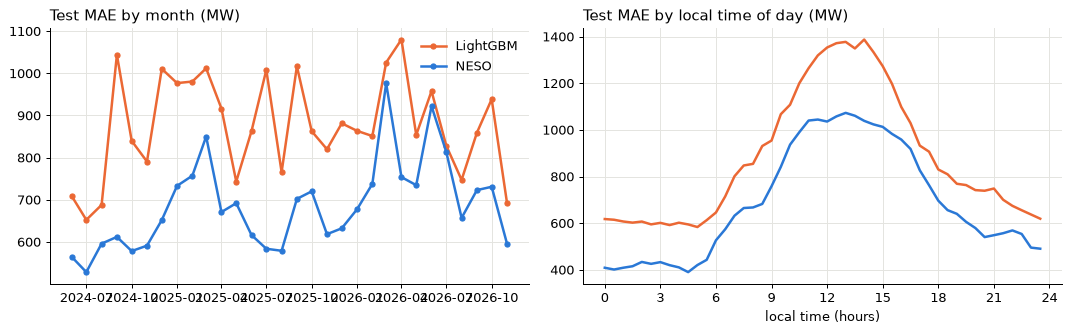

months where LightGBM beats NESO: 0 of 30


In [9]:
monthly = abs_err.groupby(test_run["fold"]).mean()
by_slot = abs_err.groupby(test_run["slot"] / 2).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, color in [("LightGBM", ORANGE), ("NESO", BLUE)]:
    axes[0].plot(pd.to_datetime(monthly.index), monthly[name], color=color, marker="o", markersize=4, label=name)
    axes[1].plot(by_slot.index, by_slot[name], color=color, label=name)
axes[0].set_title("Test MAE by month (MW)", loc="left")
axes[1].set_title("Test MAE by local time of day (MW)", loc="left")
axes[1].set_xticks(range(0, 25, 3))
axes[1].set_xlabel("local time (hours)")
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()
print("months where LightGBM beats NESO:", int((monthly["LightGBM"] < monthly["NESO"]).sum()), "of", len(monthly))


**Found (test window, 1 June 2024 to 9 November 2026, 42,818 half-hours):**

- **NESO is clearly better:** MAE 689 MW against 880 MW for our point forecast, which is 28% worse.
  MAPE is 2.8% against 3.6%.
- **We lose in all 30 months**, and in every season and part of the day. The gap is largest at
  midday (270 MW) and in autumn and winter (about 230 MW), smallest in summer and spring
  (150 to 160 MW).
- Our forecast leans high on average (+76 MW); NESO's bias is near zero.
- The validation gap with actual weather was 174 MW (notebook 06); on the test window with forecast
  weather it is 191 MW. So the honest result is close to what validation suggested, which means the
  validation setup was not flattering the model.


## Step 5. Special days: TRIADs, bank holidays, Christmas

**What:** the same comparison on the periods notebooks 02 and 03 flagged. For TRIAD periods,
NESO scores itself against the TRIAD-corrected outturn, so both are shown.


In [10]:
triad = test_run.merge(bench[["start_utc", "TRIAD_Avoidance_Estimate", "TRIAD_Avoidance_Corrected_Demand_Outturn"]],
                       on="start_utc", how="left")
is_triad = triad["TRIAD_Avoidance_Estimate"].fillna(0) != 0
day = pd.to_datetime(test_run["Date"])
bank = pd.to_datetime(list(holidays.UK(subdiv="ENG", years=range(2024, 2027))))
christmas = ((day.dt.month == 12) & (day.dt.day >= 20)) | ((day.dt.month == 1) & (day.dt.day <= 7))

rows = {}
for label, mask, actual in [
    ("TRIAD periods, plain outturn", is_triad, y),
    ("TRIAD periods, corrected outturn", is_triad, triad["TRIAD_Avoidance_Corrected_Demand_Outturn"]),
    ("bank holidays", day.isin(bank), y),
    ("Christmas period", christmas, y),
    ("all other days", ~(day.isin(bank) | christmas), y),
]:
    rows[label] = {"half-hours": int(mask.sum()),
                   "NESO MAE": (test_run.loc[mask, "Demand_Forecast"] - actual[mask]).abs().mean(),
                   "LightGBM MAE": (test_run.loc[mask, "point"] - actual[mask]).abs().mean()}
pd.DataFrame(rows).T.round(0)


,half-hours,NESO MAE,LightGBM MAE
"TRIAD periods, plain outturn",54.0,806.0,799.0
"TRIAD periods, corrected outturn",54.0,874.0,903.0
bank holidays,816.0,695.0,1439.0
Christmas period,1824.0,761.0,1190.0
all other days,40466.0,684.0,861.0


**Found:**

- **TRIAD periods:** our forecast is level with NESO on the 54 TRIAD half-hours (799 against
  806 MW on plain outturn). Against the TRIAD-corrected outturn NESO is a little better (874
  against 903 MW). These are the winter peaks where large users cut demand, and neither forecast
  handles them much worse than an ordinary winter evening.
- **Bank holidays are our weak point:** 1,439 MW against NESO's 695 MW, twice NESO's error.
  The holiday flag and the Sunday reference are not enough. My guess is that with only
  eight or so bank holidays a year, the model has seen too few to learn each one's pattern.
- **Christmas period:** 1,190 MW against 761 MW.
- On all other days the gap is 177 MW (861 against 684 MW).


## Step 6. The intervals on the test window

**What:** coverage and width of the raw and calibrated intervals, overall, by season and by part
of the day, and the pinball loss of the quantiles.

**Why it matters:** NESO's published day-ahead forecast is a single value. If our intervals hold
their coverage on unseen data with forecast weather, that is information NESO's forecast does not give.


In [11]:
def pinball(y, f, q):
    diff = y - f
    return np.mean(np.maximum(q * diff, (q - 1) * diff))


rows = {}
for low, high in INTERVALS:
    rows[f"{high - low:.0%} interval"] = {
        "raw coverage": coverage(test_run, low, high),
        "calibrated coverage": coverage(test_run, low, high, f"c{low}", f"c{high}"),
        "raw width (MW)": (test_run[f"q{high}"] - test_run[f"q{low}"]).mean(),
        "calibrated width (MW)": (test_run[f"c{high}"] - test_run[f"c{low}"]).mean(),
    }
print("90% interval score, raw quantiles:", round(interval_score(test_run, lo_col="q0.05", hi_col="q0.95"), 0),
      "MW; calibrated:", round(interval_score(test_run), 0), "MW")
print("mean pinball loss of the raw quantiles:",
      round(np.mean([pinball(y, test_run[f"q{q}"], q) for q in QUANTILES]), 1), "MW")
pd.DataFrame(rows).T.round(3)


90% interval score, raw quantiles: 6080.0 MW; calibrated: 4698.0 MW
mean pinball loss of the raw quantiles: 281.1 MW


,raw coverage,calibrated coverage,raw width (MW),calibrated width (MW)
50% interval,0.310,0.494,905.361,1479.930
80% interval,0.565,0.791,1873.640,2785.699
90% interval,0.721,0.885,2695.080,3535.574


In [12]:
inside = (y >= test_run["c0.05"]) & (y <= test_run["c0.95"])
pd.DataFrame({"by season": inside.groupby(test_run["season"]).mean(),
              "by part of day": inside.groupby(test_run["part"]).mean()}).round(3)


,by season,by part of day
autumn,0.867,NaN
evening,NaN,0.886
midday,NaN,0.882
morning,NaN,0.890
night,NaN,0.882
spring,0.873,NaN
summer,0.928,NaN
winter,0.856,NaN


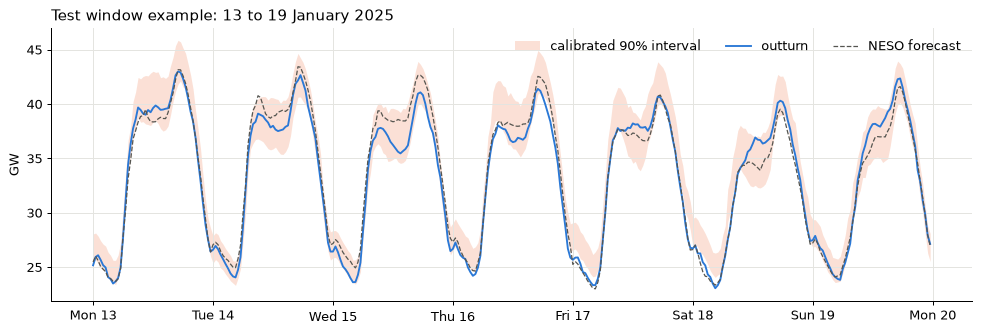

In [13]:
week = test_run[test_run["Date"].between("2025-01-13", "2025-01-19")]
hours = (week["start_utc"] - week["start_utc"].min()).dt.total_seconds() / 3600

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(hours, week["c0.05"] / 1000, week["c0.95"] / 1000, color=ORANGE, alpha=0.2, linewidth=0,
                label="calibrated 90% interval")
ax.plot(hours, week["Demand_Outturn"] / 1000, color=BLUE, linewidth=1.5, label="outturn")
ax.plot(hours, week["Demand_Forecast"] / 1000, color="#555550", linewidth=1, linestyle="--", label="NESO forecast")
ax.set_xticks(range(0, 169, 24))
ax.set_xticklabels(pd.date_range("2025-01-13", periods=8).strftime("%a %d"))
ax.set_ylabel("GW")
ax.set_title("Test window example: 13 to 19 January 2025", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper right")
fig.tight_layout()
plt.show()


**Found:**

- **The calibrated intervals hold up on unseen data with forecast weather:** the 50%, 80% and 90%
  intervals contain the outcome 49%, 79% and 89% of the time.
- Raw quantile models would have covered 31%, 57% and 72%, so the calibration step is essential.
- The 90% interval score falls from 6,080 MW (raw) to 4,698 MW (calibrated).
- Coverage is even through the day (88% to 89% in each part) and across seasons from 86%
  (winter) to 93% (summer).
- The calibrated 90% interval is about 3.5 GW wide on average. That is wide, but it is honest:
  it reflects the errors this model actually makes.
- In the example week, the outturn stays inside the band almost everywhere, and the band is
  widest on the weekday mornings and middays where errors are largest.


## Step 7. The largest misses

**What:** the days where our forecast was furthest off, with NESO's error on the same days.

**Why:** notebook 02 found NESO's worst test day was 29 March 2026, a large midday miss. Checking
whether we miss the same days shows whether the errors come from shared inputs (weather forecasts)
or from something specific to one model.


In [14]:
daily = abs_err.groupby(test_run["Date"]).mean()
worst = daily.sort_values("LightGBM", ascending=False).head(8).round(0)
print("correlation of daily MAE, LightGBM vs NESO:", round(daily["LightGBM"].corr(daily["NESO"]), 2))
worst


correlation of daily MAE, LightGBM vs NESO: 0.19


,NESO,LightGBM
Date,,
2024-12-25,395.0,2888.0
2025-08-25,442.0,2767.0
2026-01-02,1129.0,2733.0
2025-12-25,546.0,2663.0
2024-12-31,660.0,2246.0
2026-07-02,680.0,2200.0
2025-09-26,690.0,2193.0
2025-01-08,609.0,2165.0


**Found:**

- Our worst days are mostly holidays: Christmas Day 2024 and 2025, the August bank holiday 2025,
  New Year's Eve 2024 and 2 January 2026. On those days NESO's error was between 395 and 1,129 MW,
  ours 2,200 to 2,900 MW.
- The daily errors of the two forecasts are only weakly related (correlation 0.19). So our misses
  are mostly our own, not shared weather-forecast failures. NESO's worst test day from notebook 02
  (29 March 2026) is not among ours.
- This points to the clearest next step: better handling of holidays and the Christmas period,
  for example features for the days around each holiday, or a separate holiday adjustment learnt
  from all years.


## Summary

**The final test** (1 June 2024 to 9 November 2026, forecast weather, rules from notebook 04):

| | NESO | Our model |
|---|---|---|
| MAE | 689 MW | 880 MW |
| MAPE | 2.8% | 3.6% |
| Months better than the other | 30 of 30 | 0 of 30 |
| TRIAD periods (MAE, plain outturn) | 806 MW | 799 MW |
| Bank holidays (MAE) | 695 MW | 1,439 MW |
| 90% interval coverage | no interval published | 88.5% |

**What this shows**
- With public data, ten weather points and a single LightGBM model, the point forecast is 28%
  less accurate than NESO's. The gap is largest at midday and on holidays.
- The probabilistic forecast is well calibrated on unseen data: its intervals contain the outcome
  about as often as they claim, in every season and at every time of day. NESO's published
  day-ahead forecast gives no interval.
- The honest result was close to the validation estimate, so the time-ordered validation and the
  cut-off rules did their job.

**Clear next steps if I continue:** holiday and Christmas features; more weather locations
weighted by where embedded solar is installed; more than one weather model.

**Next (Day 9):** move the code into a tested Python package with a reproducible pipeline.
